# DSC624 Assignment 1 | Task 2: Supply-chain risk detection
### Google Colab project notebook — traditional ML vs. transformer embeddings

**Question:** Can semantic representations of product, destination and shipping-context text improve prediction of `Late_delivery_risk` compared with a numeric-only classifier?

**Experimental design:** One dataset (DataCo SMART Supply Chain), an order-grouped chronological holdout, three comparable Random Forest classifiers, and paired bootstrap analysis of the held-out F1 difference.


## 1 | Install dependencies

This cell is safe in a fresh Colab runtime. The primary ML/data-science libraries are already provided by Colab; only missing project-specific packages are installed. If Colab reports a dependency conflict, restart the runtime and run the notebook again.

In [1]:
%pip -q install "kagglehub>=1.0.2" "sentence-transformers>=3.0" "python-docx>=1.1"

In [2]:
import json, platform, random, sys, warnings, zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from IPython.display import display

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
    recall_score, roc_auc_score
)

SEED = 42
MAX_ROWS = 12_000         # CPU-friendly default. Set to None for the full dataset.
REDUCED_DIM = 32         # Same number of extra text features in both text models.
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
DATASET_HANDLE = "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
DATASET_URL = f"https://www.kaggle.com/datasets/{DATASET_HANDLE}"
TARGET = "Late_delivery_risk"
ORDER_ID = "Order Id"
ORDER_DATE = "order date (DateOrders)"
OUTPUT_DIR = Path('/content/dsc624_task2_results' if Path('/content').exists() else 'dsc624_task2_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | PyTorch {torch.__version__} | device: {DEVICE}")
print(f"Maximum sampled records: {MAX_ROWS or 'ALL'} | Output: {OUTPUT_DIR}")

Python 3.13.18 | scikit-learn 1.6.1 | PyTorch 2.11.0+cpu | device: cpu
Maximum sampled records: 12000 | Output: /content/dsc624_task2_results


## 2 | Load the one permitted dataset

First attempts an automatic public download using KaggleHub. If it fails due to terms/permissions or connectivity, the cell requests a **manual upload of `DataCoSupplyChainDataset.csv`**. You can get that file from the [DataCo Kaggle page](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis).

The CSV uses Latin-1 encoding. No other dataset is needed. Do not share Kaggle API tokens inside notebook cells.

In [3]:
import kagglehub

try:
    root = Path(kagglehub.dataset_download(DATASET_HANDLE))
    matches = sorted(root.rglob('DataCoSupplyChainDataset.csv'))
    if not matches:
        raise FileNotFoundError(f"DataCoSupplyChainDataset.csv not found under {root}")
    data_path = matches[0]
except Exception as exc:
    print('Automatic dataset download unavailable:', str(exc)[:350])
    print('Upload DataCoSupplyChainDataset.csv from Kaggle to continue.')
    try:
        from google.colab import files
        uploaded = files.upload()
        choices = [Path(fname) for fname in uploaded if Path(fname).name == 'DataCoSupplyChainDataset.csv']
        if not choices:
            raise FileNotFoundError('Please upload the file named DataCoSupplyChainDataset.csv')
        data_path = choices[0]
    except ImportError as err:
        raise RuntimeError('Outside Colab, place the DataCo CSV in the working directory.') from err

df = pd.read_csv(data_path, encoding='latin-1', low_memory=False)
df.columns = df.columns.str.strip()
print('Loaded:', data_path, '| rows:', f'{len(df):,}', '| columns:', len(df.columns))
display(df[[c for c in [ORDER_DATE, TARGET, 'Product Name', 'Shipping Mode'] if c in df.columns]].head(3))

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.
Loaded: /kaggle/input/dataco-smart-supply-chain-for-big-data-analysis/DataCoSupplyChainDataset.csv | rows: 180,519 | columns: 53


,order date (DateOrders),Late_delivery_risk,Product Name,Shipping Mode
0,1/31/2018 22:56,0,Smart watch,Standard Class
1,1/13/2018 12:27,1,Smart watch,Standard Class
2,1/13/2018 12:06,0,Smart watch,Standard Class


## 3 | Target definition, leakage exclusions and temporal split

Predict whether an order faces **late-delivery risk at the time of ordering**. We use the original binary `Late_delivery_risk` label. We never pass `Delivery Status`, **actual** shipping days, shipping date, order status, or the label into the features: these can contain information learned only after placement.

Orders can have multiple line items. **All line items of a given `Order Id` must stay together**. The newest ~20% of orders become the test set by their order dates; missing-date orders are excluded. Sampling (if configured) occurs *after* the split, keeping the holdout isolated.

In [4]:
required = [ORDER_ID, ORDER_DATE, TARGET]
missing = [name for name in required if name not in df.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}. Available columns: {list(df.columns)}')

df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
df[ORDER_DATE] = pd.to_datetime(df[ORDER_DATE], errors='coerce', format='mixed')
df = df.loc[df[TARGET].isin((0, 1)) & df[ORDER_DATE].notna() & df[ORDER_ID].notna()].copy()
df[TARGET] = df[TARGET].astype('int8')

order_dates = df.groupby(ORDER_ID, sort=False)[ORDER_DATE].min()
if len(order_dates) < 20 or order_dates.nunique() < 5:
    raise ValueError('Not enough dated orders for a defensible chronological holdout split.')
cutoff = order_dates.quantile(.80)
train_order_ids = set(order_dates.index[order_dates < cutoff])
test_order_ids = set(order_dates.index[order_dates >= cutoff])
assert train_order_ids.isdisjoint(test_order_ids)

train_raw = df.loc[df[ORDER_ID].isin(train_order_ids)].copy()
test_raw = df.loc[df[ORDER_ID].isin(test_order_ids)].copy()
if MAX_ROWS is not None:
    n_train = min(len(train_raw), int(MAX_ROWS * 0.8))
    n_test = min(len(test_raw), int(MAX_ROWS * 0.2))
    train_raw = train_raw.sample(n=n_train, random_state=SEED).copy()
    test_raw = test_raw.sample(n=n_test, random_state=SEED).copy()

assert set(train_raw[ORDER_ID]).isdisjoint(set(test_raw[ORDER_ID]))
assert train_raw[ORDER_DATE].max() <= test_raw[ORDER_DATE].min()
assert train_raw[TARGET].nunique() == 2 and test_raw[TARGET].nunique() == 2, 'Both classes are needed in each split.'

split_summary = pd.DataFrame({
    'Partition':['Training','Test'],
    'Rows':[len(train_raw),len(test_raw)],
    'Unique orders':[train_raw[ORDER_ID].nunique(), test_raw[ORDER_ID].nunique()],
    'Late-risk rate':[train_raw[TARGET].mean(), test_raw[TARGET].mean()],
    'Earliest order':[train_raw[ORDER_DATE].min(), test_raw[ORDER_DATE].min()],
    'Latest order':[train_raw[ORDER_DATE].max(), test_raw[ORDER_DATE].max()],
})
display(split_summary)
print('Chronological cutoff:', cutoff)

,Partition,Rows,Unique orders,Late-risk rate,Earliest order,Latest order
0,Training,9600,8852,0.552813,2015-01-01 00:21:00,2017-07-09 22:11:00
1,Test,2400,2184,0.530833,2017-07-10 00:38:00,2018-01-31 23:38:00


Chronological cutoff: 2017-07-09 23:09:48


## 4 | Feature groups

The **numeric-only** model sees quantities, prices, discounts, scheduled shipping days, and location coordinates. Both **text-augmented** models see those identical numeric fields **plus** metadata *available at order time*: product/category/department names, destination, market, customer segment, and selected shipping mode.

**Dataset limitation:** the dataset does not reliably provide rich free-text delay notes; these are *categorical metadata serialized as labeled text*, not genuine unstructured log narratives. Thus semantic embeddings may or may not outperform TF-IDF. This is an ablation study, not a guaranteed improvement.

In [5]:
NUMERIC_COLS = [
    'Days for shipment (scheduled)', 'Order Item Quantity',
    'Order Item Product Price', 'Order Item Discount',
    'Order Item Discount Rate', 'Order Item Total',
    'Product Price', 'Latitude', 'Longitude',
]
TEXT_COLS = [
    'Product Name', 'Category Name', 'Department Name',
    'Shipping Mode', 'Customer Segment', 'Order City',
    'Order State', 'Order Country', 'Order Region', 'Market',
]
LEAKY_EXCLUDED = [
    TARGET, 'Delivery Status', 'Days for shipping (real)',
    'shipping date (DateOrders)', 'Order Status',
    'Benefit per order', 'Order Profit Per Order',
]

missing_features = sorted(set(NUMERIC_COLS + TEXT_COLS) - set(df.columns))
if missing_features:
    raise ValueError(f'Expected DataCo columns unavailable: {missing_features}')

imputer = SimpleImputer(strategy='median')
num_train_raw = train_raw[NUMERIC_COLS].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
num_test_raw = test_raw[NUMERIC_COLS].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
X_train_numeric = imputer.fit_transform(num_train_raw).astype('float32')
X_test_numeric = imputer.transform(num_test_raw).astype('float32')
y_train = train_raw[TARGET].to_numpy(dtype='int32')
y_test = test_raw[TARGET].to_numpy(dtype='int32')

def make_text(frame):
    columns = frame[TEXT_COLS].fillna('unknown').astype(str)
    # Labels turn structured metadata into concise, semantically readable text.
    pieces = [col + ': ' + columns[col].str.strip() for col in TEXT_COLS]
    return pd.concat(pieces, axis=1).agg(' | '.join, axis=1).tolist()

train_text = make_text(train_raw)
test_text = make_text(test_raw)
print('Numerical features:', NUMERIC_COLS)
print('Text metadata fields:', TEXT_COLS)
print('Example text document:', train_text[0][:350])

Numerical features: ['Days for shipment (scheduled)', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Total', 'Product Price', 'Latitude', 'Longitude']
Text metadata fields: ['Product Name', 'Category Name', 'Department Name', 'Shipping Mode', 'Customer Segment', 'Order City', 'Order State', 'Order Country', 'Order Region', 'Market']
Example text document: Product Name: Field & Stream Sportsman 16 Gun Fire Safe | Category Name: Fishing | Department Name: Fan Shop | Shipping Mode: Standard Class | Customer Segment: Consumer | Order City: San Salvador | Order State: San Salvador | Order Country: El Salvador | Order Region: Central America | Market: LATAM


## 5 | Fair model evaluation helper

All three arms use the **same** Random Forest hyperparameters, sampled rows, label, threshold, and fixed chronological holdout. We do not tune against the final test set. F1 is the primary metric; precision, recall, accuracy, ROC-AUC and average precision are secondary.

In [6]:
results = []
predictions = {}
models = {}

def fit_and_evaluate(name, X_train, X_test):
    clf = RandomForestClassifier(
        n_estimators=120, max_depth=16, min_samples_leaf=2,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED,
    )
    clf.fit(X_train, y_train)
    score = clf.predict_proba(X_test)[:, 1]
    predicted = (score >= 0.5).astype('int32')
    result = {
        'model': name,
        'accuracy': accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted, zero_division=0),
        'f1': f1_score(y_test, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_test, score),
        'average_precision': average_precision_score(y_test, score),
    }
    results.append(result)
    predictions[name] = {'predicted': predicted, 'score': score}
    models[name] = clf
    print(f"{name:26s} | F1={result['f1']:.4f} | Recall={result['recall']:.4f} | ROC-AUC={result['roc_auc']:.4f}")
    return clf

## 6 | Model A: traditional numeric-only Random Forest

In [7]:
model_numeric = fit_and_evaluate('Numeric only', X_train_numeric, X_test_numeric)

Numeric only               | F1=0.6742 | Recall=0.5840 | ROC-AUC=0.7326


## 7 | Model B: numeric + TF-IDF (non-LLM text ablation)

TF-IDF is fitted **only on training text**, then reduced to the same number of extra dimensions used for the transformer embeddings. This measures whether adding text helps *without* a transformer.

In [8]:
vectorizer = TfidfVectorizer(min_df=2, max_features=3_000, ngram_range=(1, 2), sublinear_tf=True)
train_tfidf = vectorizer.fit_transform(train_text)
test_tfidf = vectorizer.transform(test_text)
svd_dim = min(REDUCED_DIM, train_tfidf.shape[1] - 1, train_tfidf.shape[0] - 1)
if svd_dim < 1:
    raise ValueError('Not enough text vocabulary for TF-IDF; increase MAX_ROWS.')
svd = TruncatedSVD(n_components=svd_dim, random_state=SEED)
train_tfidf_small = svd.fit_transform(train_tfidf).astype('float32')
test_tfidf_small = svd.transform(test_tfidf).astype('float32')
X_train_tfidf = np.hstack([X_train_numeric, train_tfidf_small])
X_test_tfidf = np.hstack([X_test_numeric, test_tfidf_small])
model_tfidf = fit_and_evaluate('Numeric + TF-IDF', X_train_tfidf, X_test_tfidf)

Numeric + TF-IDF           | F1=0.6681 | Recall=0.5973 | ROC-AUC=0.7326


## 8 | Model C: numeric + pretrained transformer embeddings

[all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) is an open-weights **sentence-transformer encoding model** with 384-dimensional embeddings. It is *not* a chat or generative LLM. Task 2 specifically allows a **pretrained embedding model** for semantic vectors, so it is an efficient choice for Colab. Repeated metadata strings are encoded only once, and PCA is fitted on the training set only.

In [9]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
all_unique_texts = list(dict.fromkeys(train_text + test_text))
print(f'Encoding {len(all_unique_texts):,} distinct text records from {len(train_text)+len(test_text):,} rows.')
unique_embeddings = encoder.encode(
    all_unique_texts, batch_size=64 if DEVICE == 'cuda' else 32,
    show_progress_bar=True, convert_to_numpy=True,
    normalize_embeddings=True,
)
text_index = pd.Index(all_unique_texts)
train_emb = unique_embeddings[text_index.get_indexer(train_text)].astype('float32')
test_emb = unique_embeddings[text_index.get_indexer(test_text)].astype('float32')
pca_dim = min(REDUCED_DIM, train_emb.shape[1], train_emb.shape[0] - 1)
pca = PCA(n_components=pca_dim, svd_solver='randomized', random_state=SEED)
train_emb_small = pca.fit_transform(train_emb).astype('float32')
test_emb_small = pca.transform(test_emb).astype('float32')
X_train_hybrid = np.hstack([X_train_numeric, train_emb_small])
X_test_hybrid = np.hstack([X_test_numeric, test_emb_small])
print('Raw embedding dimensions:', train_emb.shape[1], '| PCA dimensions:', pca_dim)
model_hybrid = fit_and_evaluate('Numeric + transformer', X_train_hybrid, X_test_hybrid)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoding 10,594 distinct text records from 12,000 rows.


Batches:   0%|          | 0/332 [00:00<?, ?it/s]

Raw embedding dimensions: 384 | PCA dimensions: 32
Numeric + transformer      | F1=0.6839 | Recall=0.6217 | ROC-AUC=0.7306


## 9 | Compare all models on the untouched test set

**Do not assert that the transformer model wins**: its performance must be measured. The F1 difference reported here is measured on exactly the same held-out records.

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Numeric + transformer,0.6950,0.7601,0.6217,0.6839,0.7306,0.7747
1,Numeric only,0.7004,0.7974,0.5840,0.6742,0.7326,0.7882
2,Numeric + TF-IDF,0.6850,0.7580,0.5973,0.6681,0.7326,0.7845


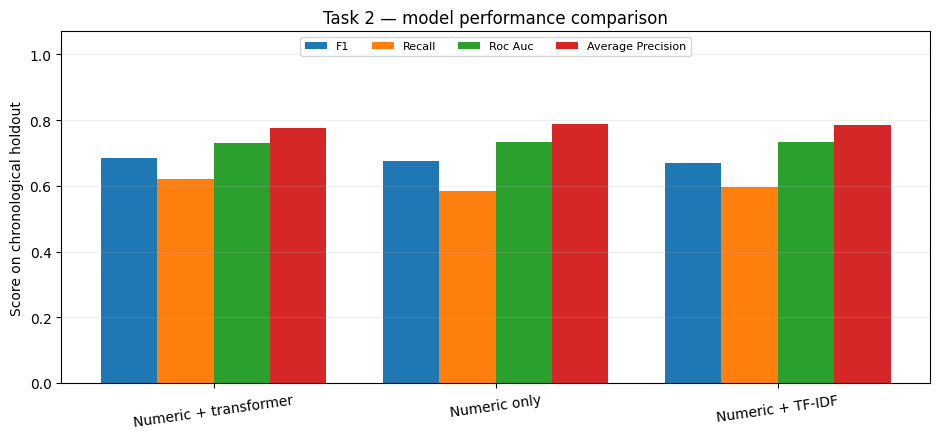

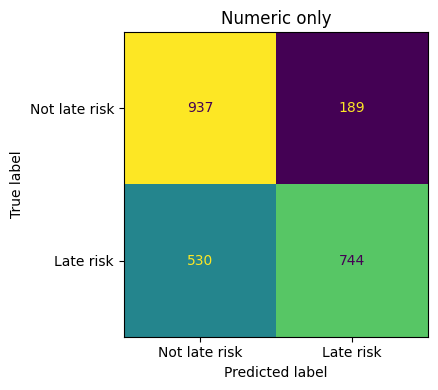

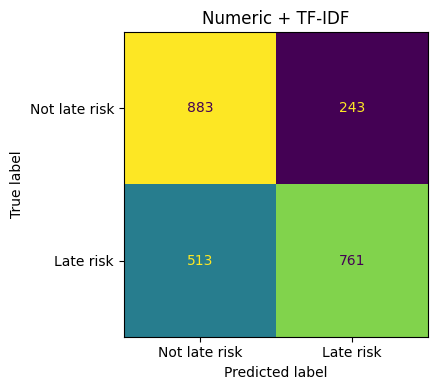

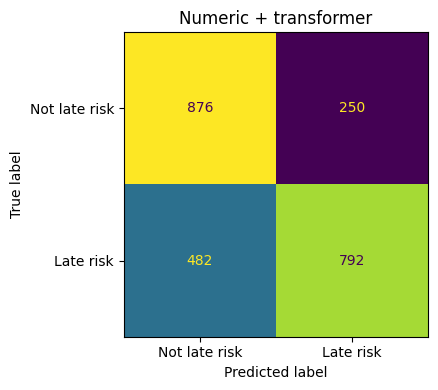

In [10]:
results_df = pd.DataFrame(results).sort_values('f1', ascending=False).reset_index(drop=True)
display(results_df.style.format({x: '{:.4f}' for x in ['accuracy','precision','recall','f1','roc_auc','average_precision']}))
results_df.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)

metric_cols = ['f1', 'recall', 'roc_auc', 'average_precision']
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(results_df))
w = .20
for i, key in enumerate(metric_cols):
    ax.bar(x + (i - 1.5) * w, results_df[key].values, width=w, label=key.replace('_',' ').title())
ax.set_xticks(x, results_df['model'], rotation=8)
ax.set_ylim(0, 1.07)
ax.set_ylabel('Score on chronological holdout')
ax.set_title('Task 2 — model performance comparison')
ax.legend(ncol=4, loc='upper center', fontsize=8)
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=180)
plt.show()

for model_name, pred_dict in predictions.items():
    fig, ax = plt.subplots(figsize=(4.7, 4))
    cm = confusion_matrix(y_test, pred_dict['predicted'], labels=[0,1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not late risk','Late risk'])
    disp.plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(model_name)
    fig.tight_layout()
    safe_name = model_name.lower().replace(' + ', '_').replace(' ', '_').replace('-', '')
    fig.savefig(OUTPUT_DIR / f'confusion_{safe_name}.png', dpi=180)
    plt.show()

## 10 | Paired bootstrap confidence interval of F1 gain

Bootstrap-resample **test indices together** for both classifiers (500 replicates). A 95% percentile interval that crosses zero means the measured F1 difference is uncertain at this sample size. This is descriptive uncertainty estimation, **not** evidence of causal effects.

In [11]:
base_pred = predictions['Numeric only']['predicted']
hybrid_pred = predictions['Numeric + transformer']['predicted']
observed_delta = f1_score(y_test, hybrid_pred) - f1_score(y_test, base_pred)
rng = np.random.default_rng(SEED)
deltas = []
for _ in range(500):
    idx = rng.integers(0, len(y_test), size=len(y_test))
    # F1 is defined even if a rare bootstrap sample lacks positive predictions.
    deltas.append(
        f1_score(y_test[idx], hybrid_pred[idx], zero_division=0)
        - f1_score(y_test[idx], base_pred[idx], zero_division=0)
    )
ci_low, ci_high = np.percentile(deltas, [2.5, 97.5])
if ci_low > 0:
    interpretation = 'Hybrid improvement is positive throughout the paired 95% bootstrap interval.'
elif ci_high < 0:
    interpretation = 'Hybrid performance is lower throughout the paired 95% bootstrap interval.'
else:
    interpretation = 'The 95% bootstrap interval spans zero; a clear F1 advantage was not established.'
print(f'F1 hybrid minus numeric: {observed_delta:+.4f} (95% bootstrap CI: {ci_low:+.4f} to {ci_high:+.4f})')
print(interpretation)

F1 hybrid minus numeric: +0.0097 (95% bootstrap CI: -0.0042 to +0.0221)
The 95% bootstrap interval spans zero; a clear F1 advantage was not established.


## 11 | Save reproducible details and auto-generate the six-page-limit report draft

The report **uses the actual metrics computed above**; no example scores are inserted. Read the generated draft and add your own literature review, discussion and personal details before submission. The Word document is formatted to fit the assignment's **at-most-six-page** limit for a default-sized run; verify page count after editing.

In [12]:
import sklearn
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_CELL_VERTICAL_ALIGNMENT

summary = {
    'dataset': DATASET_URL,
    'dataset_csv': 'DataCoSupplyChainDataset.csv',
    'sample_limit': MAX_ROWS,
    'train_rows': len(train_raw), 'test_rows': len(test_raw),
    'train_unique_orders': int(train_raw[ORDER_ID].nunique()),
    'test_unique_orders': int(test_raw[ORDER_ID].nunique()),
    'train_late_risk_fraction': float(train_raw[TARGET].mean()),
    'test_late_risk_fraction': float(test_raw[TARGET].mean()),
    'temporal_cutoff': str(cutoff),
    'random_seed': SEED, 'embedding_model': EMBEDDING_MODEL,
    'device': DEVICE, 'numpy_version': np.__version__,
    'scikit_learn_version': sklearn.__version__,
    'numeric_features': NUMERIC_COLS, 'text_features': TEXT_COLS,
    'excluded_outcome_fields': LEAKY_EXCLUDED,
    'delta_f1': float(observed_delta),
    'f1_bootstrap_95_ci': [float(ci_low), float(ci_high)],
    'interpretation': interpretation,
    'models': results_df.to_dict(orient='records'),
    'created_utc': datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_DIR / 'experiment_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

def add_heading_and_text(doc, title, body):
    doc.add_heading(title, level=1)
    doc.add_paragraph(body)

doc = Document()
section = doc.sections[0]
section.top_margin = section.bottom_margin = Inches(.76)
section.left_margin = section.right_margin = Inches(.82)
styles = doc.styles
styles['Normal'].font.name = 'Arial'
styles['Normal'].font.size = Pt(10.5)
styles['Normal'].paragraph_format.space_after = Pt(5)
for st in ['Title','Heading 1','Heading 2']:
    styles[st].font.name = 'Arial'
    styles[st].font.color.rgb = RGBColor(25, 51, 81)

p = doc.add_paragraph(style='Title')
p.add_run('Hybrid Supply-Chain Late-Delivery Risk Prediction')
p = doc.add_paragraph('DSC624 — Natural Language Processing and Large Language Models | Assignment 1 | Task 2')
p.style = 'Subtitle'
doc.add_paragraph('Student: __________________________    Student ID: __________________________')

baseline = next(r for r in results if r['model'] == 'Numeric only')
hybrid = next(r for r in results if r['model'] == 'Numeric + transformer')

add_heading_and_text(doc, 'Abstract',
    f'This study tests whether pretrained transformer embeddings improve supply-chain late-delivery risk '
    f'classification on the DataCo SMART dataset. A numeric-only Random Forest is compared with '
    f'a numeric + TF-IDF control and a numeric + MiniLM transformer model using an order-grouped '
    f'chronological holdout ({len(train_raw):,} training rows; {len(test_raw):,} test rows). '
    f'The baseline achieves F1={baseline["f1"]:.3f}; the transformer hybrid achieves F1={hybrid["f1"]:.3f}. '
    f'The paired F1 difference is {observed_delta:+.3f} (95% bootstrap interval {ci_low:+.3f} to {ci_high:+.3f}). '
    + interpretation)
add_heading_and_text(doc, '1. Introduction and research question',
    'Late shipments disrupt customer experience and logistics planning. This assignment examines '
    'whether semantic representations of order-time text metadata add predictive value beyond numeric '
    'sales and shipping attributes. The binary label is Late_delivery_risk; the intended use is '
    'risk triage at order placement, not post-delivery status classification.')
add_heading_and_text(doc, '2. Dataset, preparation and leakage control',
    f'DataCo SMART Supply Chain contains 180,519 rows in the published dataset. The experiment '
    f'reads DataCoSupplyChainDataset.csv and uses {len(train_raw)+len(test_raw):,} rows after '
    f'chronological partitioning and optional sampling. Train and test groups are disjoint on Order Id. '
    f'The holdout starts at {cutoff}. The positive-label rate is {train_raw[TARGET].mean():.1%} '
    f'in training and {test_raw[TARGET].mean():.1%} in test. Delivery Status, Days for shipping (real), '
    'shipping date, Order Status, financial outcomes, and the target are excluded from predictors. '
    'Missing numeric values are median-imputed using training records only.')
add_heading_and_text(doc, '3. Methodology',
    'Three Random Forests use 120 trees, maximum depth 16, minimum leaf size 2, '
    'balanced subsample class weighting and random seed 42. Model A uses nine numerical attributes '
    '(quantity, price, discount, scheduled shipping days and geographic coordinates). Model B adds '
    'TF-IDF n-gram features compressed using training-fitted TruncatedSVD. Model C uses the '
    'open-weights all-MiniLM-L6-v2 sentence transformer (384 dimensions) and training-fitted PCA '
    'to reduce the text representation to 32 dimensions. Both text approaches append these features '
    'to exactly the same numeric baseline input. The embeddings are pretrained, not fine-tuned on '
    'the dataset. Model settings are fixed before testing.')

heading = doc.add_heading('4. Experimental results', 1)
tbl = doc.add_table(rows=1, cols=6)
tbl.style = 'Light Shading Accent 1'
headers = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
for j, val in enumerate(headers): tbl.rows[0].cells[j].text = val
for r in results_df.to_dict(orient='records'):
    cells = tbl.add_row().cells
    for j, val in enumerate([r['model'], *(f'{r[k]:.3f}' for k in ['accuracy','precision','recall','f1','roc_auc'])]):
        cells[j].text = str(val)
    for cell in cells: cell.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER

doc.add_paragraph('Table 1. Scores on an order-disjoint, chronological test partition (threshold 0.5).')
doc.add_picture(str(OUTPUT_DIR / 'model_comparison.png'), width=Inches(6.05))
doc.add_paragraph('Figure 1. Model performance comparison on the same held-out records.')
add_heading_and_text(doc, '5. Analysis and interpretation',
    f'The transformer hybrid changes F1 by {observed_delta:+.3f} compared with the numeric-only '
    f'baseline. A paired 500-replicate bootstrap gives a 95% interval of {ci_low:+.3f} to '
    f'{ci_high:+.3f}. {interpretation} Comparing against the TF-IDF control helps distinguish '
    'semantic-embedding utility from the benefit of introducing any text features. Recall and '
    'average precision are relevant because false negatives can overlook shipment risks; threshold '
    'selection and calibration would be needed before deployment.')
add_heading_and_text(doc, '6. Limitations and validity threats',
    'DataCo provides mostly structured categorical metadata rather than genuine narrative delay '
    'comments, limiting the expected advantage of semantic representations. The labels describe '
    'historical shipping outcomes and may not fully represent future disruptions or fraud. '
    'Results depend on the sampling limit, geography, class mix, historical period, and chosen '
    'risk threshold. An order-grouped chronological split reduces repeated-order and future-data '
    'leakage, but cannot eliminate covariate shift. Avoid using personally identifying customer '
    'fields, which are unnecessary for this task.')
add_heading_and_text(doc, '7. Reproducibility and conclusion',
    f'The accompanying Google Colab notebook installs dependencies, downloads the single Kaggle '
    f'dataset, fixes random seeds, preserves temporal order, trains all models, exports '
    f'model_comparison.csv, confusion matrices, and experiment_summary.json. Runtime: {DEVICE}; '
    f'scikit-learn {sklearn.__version__}. The study concludes only what is supported by the '
    f'held-out metrics and their uncertainty, rather than presuming the transformer model is superior.')
doc.add_heading('References', 1)
for ref in [
    '1. DataCo SMART Supply Chain for Big Data Analysis. Kaggle. ' + DATASET_URL,
    '2. Reimers, N., and Gurevych, I. (2019). Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. ACL Anthology. https://aclanthology.org/D19-1410/',
    '3. Sentence Transformers documentation. https://www.sbert.net/docs/sentence_transformer/usage/usage.html',
    '4. Scikit-learn documentation. https://scikit-learn.org/stable/',
]:
    doc.add_paragraph(ref, style='Normal')

report_path = OUTPUT_DIR / 'DSC624_Task2_Report_Draft.docx'
doc.save(report_path)
print('Generated report draft:', report_path)
print('Review, personalize, check page count (<=6), and cite any additional literature before submitting.')

Generated report draft: /content/dsc624_task2_results/DSC624_Task2_Report_Draft.docx
Review, personalize, check page count (<=6), and cite any additional literature before submitting.


## 12 | Download the Colab outputs

This ZIP contains the report draft, genuine experiment scores, plots, and configuration JSON. The notebook itself is separately saved as an `.ipynb` download from your Colab **File → Download → Download .ipynb** menu.

In [13]:
from shutil import make_archive
archive_path = make_archive(str(OUTPUT_DIR), 'zip', root_dir=OUTPUT_DIR)
print('ZIP created:', archive_path)
try:
    from google.colab import files as colab_files
    colab_files.download(archive_path)
except ImportError:
    print('Running outside Colab: retrieve the ZIP from the printed path.')

ZIP created: /content/dsc624_task2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')